# 1. Data understanding: can the inputs be matched?

This notebook establishes the data contract on a ten-image Development pilot:
match the text and catalog, verify native image/map alignment, then inspect
representative landscapes. Later notebooks expand the sample and evaluate models.

## 1. Which inputs do we need?

Sentinel-2's red, green and blue bands form the images. BigEarthNet.txt supplies
text annotations; the independent BigEarthNet-v2 catalog checks identity.
Land-cover maps provide a separate reference for later evaluation.
Neither a text answer nor a map is independently verified visual truth.
[Source and access details](../docs/DATA_ACCESS.md) remain outside the narrative.


## 2. Configuration and reproducible selection

We use the first ten distinct S2 patch IDs in ascending server row order within
rows 0–399. Selection does not inspect labels or model results. This convenience
sample is geographically concentrated and is not a representative benchmark.
The unversioned rows API is pinned by response SHA-256; changed responses fail
rather than silently replacing the pilot. Public manifests contain no local paths.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from earth_observation.data import acquire_rasters, load_pilot
from earth_observation.raster import inspect_patch, load_rgb, patch_files

ROOT = Path.cwd().parent
MANIFEST = ROOT / "manifests/data-pilot-v1.json"
CACHE = ROOT / "data/cache"
IMAGE_ROOT = ROOT / "data/raw/BigEarthNet-S2"
MAP_ROOT = ROOT / "data/raw/Reference_Maps"
DISPLAY_UPPER_DN = 3000

manifest = json.loads(MANIFEST.read_text())
patches, catalog = load_pilot(MANIFEST, CACHE)
assert len(patches) == 10
raster_paths = acquire_rasters(MANIFEST, CACHE, ROOT / "data/raw")
assert len(raster_paths) == 40
pd.DataFrame(manifest["assets"])[["name", "size_bytes"]]

,name,size_bytes
0,text-rows-0.json,55921
1,text-rows-100.json,56875
2,text-rows-200.json,55627
3,text-rows-300.json,58107
4,metadata.parquet,3616349


The pilot uses small prefixes of the official archives because its ten patches
occur near their beginning. This verifies these particular files, not arbitrary
random access. Sources and downloaded bytes are identified in the manifest.


## 3. Can the text and catalog be matched exactly?

Repeated patch IDs in the text are expected: each row is a separate instruction.
Pilot patch IDs must be unique. We join exact S2 IDs against independent v2
metadata and check the S1 pair name; filenames alone would be insufficient.

In [2]:
catalog[["patch_id", "catalog_status", "country", "split"]]

,patch_id,catalog_status,country,split
0,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
1,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
2,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
3,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
4,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
5,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
6,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
7,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
8,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test
9,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,verified,Austria,test


All ten exact patch identities and S1 pair names agree with the catalog.
All selected patches are in Austria, from one S2 tile, and carry the source `test`
split. This source split is reported metadata, not our project's final test set.
The sample must not guide future frozen evaluation choices. No raster identity or
alignment is established by a catalog join.

In [3]:
pd.DataFrame(patches)[["row_idx", "ID", "patch_id", "type", "category"]].head(3)

,row_idx,ID,patch_id,type,category
0,0,1,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency
1,25,26,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency
2,49,50,S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_2...,binary,adjacency


The first instruction for these examples is an adjacency annotation.
It is useful for inspecting the schema, but neither annotation order nor an answer
constitutes a retrieval relevance rule. No such rule is derived in this notebook.

## 4. Do image and reference rasters align?

Compare native grids, coordinate systems and footprints. Check identity first:
a plausible landscape alone cannot establish that two files describe the same
patch. No resampling or alignment repair is performed.


In [4]:
files_by_patch = {
    p["patch_id"]: patch_files(p["patch_id"], IMAGE_ROOT, MAP_ROOT) for p in patches
}
checks = {patch_id: inspect_patch(files) for patch_id, files in files_by_patch.items()}
geometry = pd.DataFrame(
    [
        {
            "grid_index": "_".join(patch_id.rsplit("_", 2)[1:]),
            "status": check["status"],
            "rgb_shape": check["rasters"]["B04"]["shape"],
            "map_shape": check["rasters"]["reference"]["shape"],
            "crs": check["rasters"]["B04"]["crs"],
            "resolution_m": check["rasters"]["B04"]["resolution"],
            "same_transform": check["rasters"]["B04"]["transform"]
            == check["rasters"]["reference"]["transform"],
        }
        for patch_id, check in checks.items()
    ]
)
display(geometry)

profiles = pd.DataFrame(
    [
        {"component": band, "dtype": profile["dtype"], "NoData": profile["nodata"]}
        for check in checks.values()
        for band, profile in check["rasters"].items()
    ]
)
profiles.groupby(["component", "dtype", "NoData"], dropna=False).size().rename("files")

,grid_index,status,rgb_shape,map_shape,crs,resolution_m,same_transform
0,26_57,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
1,27_55,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
2,27_56,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
3,27_57,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
4,27_58,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
5,27_59,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
6,27_60,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
7,27_61,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
8,28_55,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True
9,28_56,aligned,"(120, 120)","(120, 120)",EPSG:32633,"(10.0, 10.0)",True


component  dtype   NoData
B02        uint16  0.0       10
B03        uint16  0.0       10
B04        uint16  0.0       10
reference  uint16  0.0       10
Name: files, dtype: int64

In [5]:
from rasterio.warp import transform

center_errors = []
for annotation in patches:
    raster = checks[annotation["patch_id"]]["rasters"]["B04"]
    left, bottom, right, top = raster["bounds"]
    longitude, latitude = transform(
        raster["crs"], "EPSG:4326", [(left + right) / 2], [(bottom + top) / 2]
    )
    center_errors.append(
        max(
            abs(longitude[0] - annotation["longitude"]),
            abs(latitude[0] - annotation["latitude"]),
        )
    )
assert max(center_errors) < 1e-8
pd.DataFrame(
    {
        "check": [
            "Complete RGB/map patches",
            "Matched native transforms",
            "Maximum text/raster center difference (degrees)",
        ],
        "observed": [
            len(checks),
            int(geometry["same_transform"].sum()),
            max(center_errors),
        ],
    }
)

,check,observed
0,Complete RGB/map patches,1.000000e+01
1,Matched native transforms,1.000000e+01
2,Maximum text/raster center difference (degrees),7.105427e-15


All ten pairs share a 120×120 grid with 10 m cells and matching footprints.
Raster centers also match the text coordinates. This confirms technical
correspondence; it does not validate the map's class labels or boundaries.

## 5. What do selected image/map pairs show?

We display three fixed examples with the same RGB scale (raw DN/3000).
The categorical map colors retain source class IDs. Unlabeled and NoData cells
remain unknown. The display does not change the data or add reference detail.


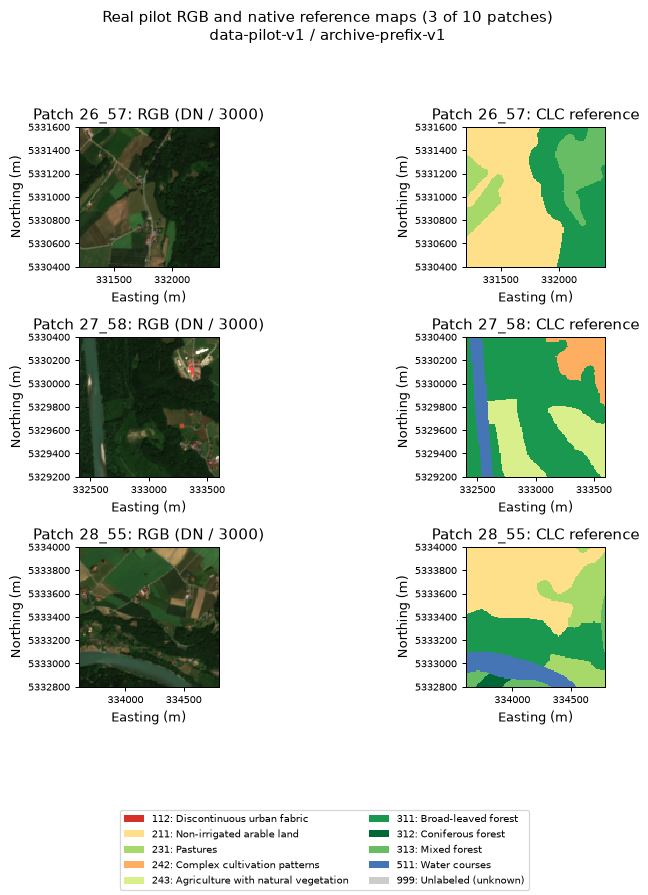

In [6]:
import numpy as np
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

# Source CLC IDs/names for display only; no benchmark mapping is defined here.
map_labels = {
    112: ("Discontinuous urban fabric", "#d73027"),
    211: ("Non-irrigated arable land", "#fee08b"),
    231: ("Pastures", "#a6d96a"),
    242: ("Complex cultivation patterns", "#fdae61"),
    243: ("Agriculture with natural vegetation", "#d9ef8b"),
    311: ("Broad-leaved forest", "#1a9850"),
    312: ("Coniferous forest", "#006837"),
    313: ("Mixed forest", "#66bd63"),
    511: ("Water courses", "#4575b4"),
    999: ("Unlabeled (unknown)", "#cccccc"),
}
class_ids = np.array(list(map_labels))
cmap = ListedColormap([value[1] for value in map_labels.values()])
norm = BoundaryNorm(np.arange(len(class_ids) + 1) - 0.5, len(class_ids))
fig, axes = plt.subplots(3, 2, figsize=(9, 10), dpi=90)
for row, index in enumerate([0, 4, 8]):
    patch_id = patches[index]["patch_id"]
    files = files_by_patch[patch_id]
    left, bottom, right, top = checks[patch_id]["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN), extent=extent, interpolation="nearest"
    )
    with rasterio.open(files["reference"]) as ds:
        reference = ds.read(1, masked=True)
    assert set(np.unique(reference.compressed())).issubset(map_labels)
    # Reindex codes only to assign discrete display colors, preserving the mask.
    display = np.ma.array(
        np.searchsorted(class_ids, reference.data), mask=np.ma.getmaskarray(reference)
    )
    axes[row, 1].imshow(
        display, extent=extent, interpolation="nearest", cmap=cmap, norm=norm
    )
    suffix = "_".join(patch_id.rsplit("_", 2)[1:])
    axes[row, 0].set_title(f"Patch {suffix}: RGB (DN / 3000)")
    axes[row, 1].set_title(f"Patch {suffix}: CLC reference")
    for ax in axes[row]:
        ax.set(xlabel="Easting (m)", ylabel="Northing (m)")
        ax.ticklabel_format(axis="both", style="plain", useOffset=False)
        ax.tick_params(labelsize=8)
        ax.set_aspect("equal")
fig.legend(
    handles=[
        Patch(facecolor=color, label=f"{code}: {label}")
        for code, (label, color) in map_labels.items()
    ],
    loc="lower center",
    ncol=2,
    fontsize=8,
)
fig.suptitle(
    "Real pilot RGB and native reference maps (3 of 10 patches)\n"
    "data-pilot-v1 / archive-prefix-v1",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.17, 1, 0.94))
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/data-pilot-v1-rgb-reference.png", dpi=110)
plt.show()

Visual inspection of these three fixed examples supports broad landscape
correspondence, without establishing the truth of individual map classes.
Patch 26_57 shows fields on the west and a dark wooded block on the east, roughly
following the mapped agricultural/forest division. RGB alone does not verify the
map's broad-leaved versus mixed-forest distinction.

Patch 27_58 shows a north–south water corridor on the west, matching the location
of the mapped water course. Bright structures and small clearings appear within
a coarsely delineated landscape; their individual boundaries are not separately
represented by these source map polygons. Patch 28_55 shows a river corridor
along the south, broadly corresponding to the reference water band, with more
fine-scale variation in fields and vegetation than the reference depicts.

The fixed RGB display is relatively dark in wooded areas. We retain that display
scale rather than applying patch-specific contrast. Native grids, exact member
identity and text-center agreement confirm technical spatial correspondence;
this qualitative inspection does not validate every boundary or class. CORINE
uncertainty remains, despite its rasterization onto 10-m cells.

## 6. Findings and next stage

The ten text/catalog identities and native RGB/map pairs match. Visual examples
show broad landscape correspondence, with finer detail in RGB than in the map.
All images come from one Austria tile, so this pilot is unsuitable for a
spatially held-out comparison.

[Notebook 02](02_benchmark_construction.ipynb) defines map relevance and builds
a larger, spatially separated benchmark. Cached rasters and detailed access
checks remain local; the source manifest makes their identities reproducible.
